# Robustness: one responder at a time, circularity, multiple testing, reproducibility, region DE on the new map

A reviewer-style pass over the claims in the README (findings 1-17). Module: `utils/robustness.py`.

* **A. Circularity.** Responders were called from OL stress (ISR) genes. Do they still stand out on genes not used for
  that call, and in cell types never used for it?
* **B. One responder at a time.** Every key per-mouse result, with each responder left out in turn, and whether each
  responder on its own lies beyond the control range. With 3 vs 6 mice the smallest exact p is 0.012; with 2 vs 6 it
  is 0.036.
* **C. Multiple testing.** Benjamini-Hochberg within each family of tests of analysis/11-14.
* **D. Reproducibility.** Which notebooks need gitignored inputs, how each is regenerated, and errors in outputs.
* **E. Region DE (analysis/01) re-run on the disease-free region map** (analysis/14).

In [1]:
import sys, re, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import robustness as rb, composition as co
from utils.gene_sets import MECHANISM_SETS
from utils.ol_response import ISR_GENES

OUT = REPO / "results" / "robustness"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; age = sections["age"]
ctrl = list(sections.index[grp == "control"]); resp = list(sections.index[grp == "responder"]); nonr = list(sections.index[grp == "non-responder"])
order = ctrl + nonr + resp

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
def save(fig, name, dpi=200):
    fig.savefig(FIG / f"{name}.png", dpi=dpi, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def dots(ax, values, title, ylab=None, ref=None):
    for gi, g in enumerate(GROUP_ORDER):
        v = values[values.index.map(grp) == g].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    if ref is not None: ax.axhline(ref, color=AXIS, lw=0.8)
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5); ax.set_title(title, fontsize=9)
    if ylab: ax.set_ylabel(ylab)

RT = REPO / "results" / "region_time"
meta = pd.read_csv(RT / "pseudobulk_meta.csv", index_col=0)
counts = pd.read_csv(RT / "pseudobulk_counts.csv", index_col=0)
def pseudobulk_log(cell_types, min_cpm=20, exclude=()):
    m = meta[(meta.region == "All regions") & meta.cell_type.isin(cell_types)]
    X = counts.loc[m.index].groupby(m.sample_id).sum().loc[order]
    cpm = X.div(X.sum(1), axis=0) * 1e6
    keep = [g for g in cpm.columns if cpm.loc[ctrl, g].mean() > min_cpm and g not in set(exclude)]
    return np.log2(cpm[keep] + 1)

## A. Circularity: do responders stand out on genes and cells not used to call them?

,"OLs, selection genes removed",microglia,astrocytes,endothelial cells,group
RB4620,0.00,0.17,0.13,0.21,control
RB4658,0.30,-0.00,0.30,-0.06,control
RB4676,0.16,0.13,0.11,0.23,control
RB4282,-0.03,-0.07,0.30,0.52,control
RB4350,0.37,0.15,0.07,0.19,control
RB4498,0.34,0.42,0.35,-0.06,control
RB4630,-0.17,-0.21,0.26,0.45,non-responder
RB4653,0.18,0.27,0.33,0.45,non-responder
RB4403,0.14,-0.09,-0.11,-0.24,non-responder
RB4627,0.57,0.57,0.29,0.37,responder


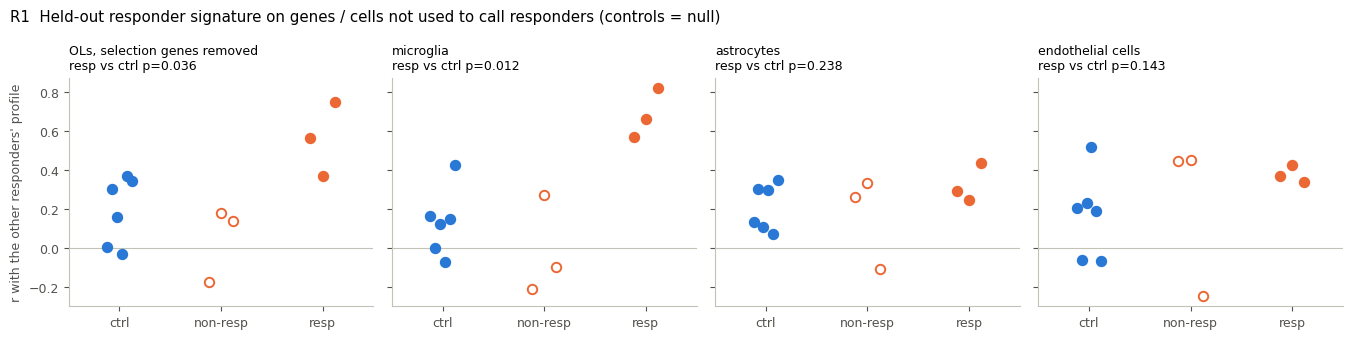

In [2]:
drivers = pd.read_csv(REPO / "results" / "ol_gene_drivers" / "tables" / "driver_genes.csv", index_col=0).index
SELECTION = set(ISR_GENES) | set(drivers) | set(MECHANISM_SETS["ATF4 / ISR"]) | set(MECHANISM_SETS["p53 targets"])
sig = {}
for lab, cts in [("OLs, selection genes removed", ["Oligodendrocytes", "DA-Oligodendrocytes"]), ("microglia", ["Microglia"]),
                 ("astrocytes", ["Astrocytes"]), ("endothelial cells", ["Endothelial Cells"])]:
    L = pseudobulk_log(cts, exclude=SELECTION)
    sig[lab] = rb.heldout_signature_r(L, age, resp, ctrl)
sig = save_table(pd.DataFrame(sig).loc[order].round(4), "heldout_signature_r")
fig, axes = plt.subplots(1, sig.shape[1], figsize=(3.4 * sig.shape[1], 3.4), sharey=True)
for ax, col in zip(axes, sig.columns):
    _, p = co.exact_perm(sig[col], resp, ctrl)
    dots(ax, sig[col], f"{col}\nresp vs ctrl p={p:.3f}", ylab="r with the other responders' profile" if ax is axes[0] else None, ref=0)
fig.suptitle("R1  Held-out responder signature on genes / cells not used to call responders (controls = null)", x=0.01, ha="left")
fig.tight_layout(); save(fig, "R1_heldout_signature")
display(sig.assign(group=grp).round(2))

**A.** Each mouse's expression profile (log2FC vs same-slide controls, its own section left out of the control
baseline) is correlated with the mean profile of the *other* responders. Because both profiles are measured against
the same control baseline, controls are not at zero; they form the null.

* **Microglia**, a cell type never used to call responders: responders correlate at 0.57-0.82 with each other's
  profile, controls at -0.07 to 0.42: complete separation. This is the cleanest independent evidence that the three
  responders share a real, common response.
* **OLs with every selection gene removed** (the ISR set, all data-derived driver genes, the ATF4 and p53 sets):
  RB4405 (0.75) and RB4627 (0.57) stand clear of controls (up to 0.37); RB4401 (0.37) only ties the highest control.
  RB4401's OL response beyond the stress genes is weak, consistent with it being the mildest responder throughout.
* Astrocytes and endothelial cells: weak or no shared profile (see table), in line with analysis/12.

## B. One responder at a time

,finding,expected,p_all,p_worst_drop_one,dropped_for_worst,n_beyond_control_range,nonresp_p
metric,,,,,,,
"OL ISR score, whole section (selection metric)",1,up,0.012,0.036,RB4627,3,0.524
OLs in control top 1 % (ISR),12,up,0.012,0.036,RB4627,3,0.464
OL held-out signature r (selection genes removed),A,up,0.036,0.107,RB4627,2,0.286
microglia held-out signature r,A,up,0.012,0.036,RB4627,3,0.357
ATF4 / ISR pathway score,16,up,0.012,0.036,RB4627,3,0.726
p53 pathway score,16,up,0.012,0.036,RB4627,3,0.750
microglia DAM score,5/15,up,0.012,0.036,RB4627,3,0.964
astrocyte reactive score,5/15,up,0.012,0.036,RB4627,3,0.726
microglia / mm2 thalamus (disease-free map),14,up,0.012,0.036,RB4627,3,0.750


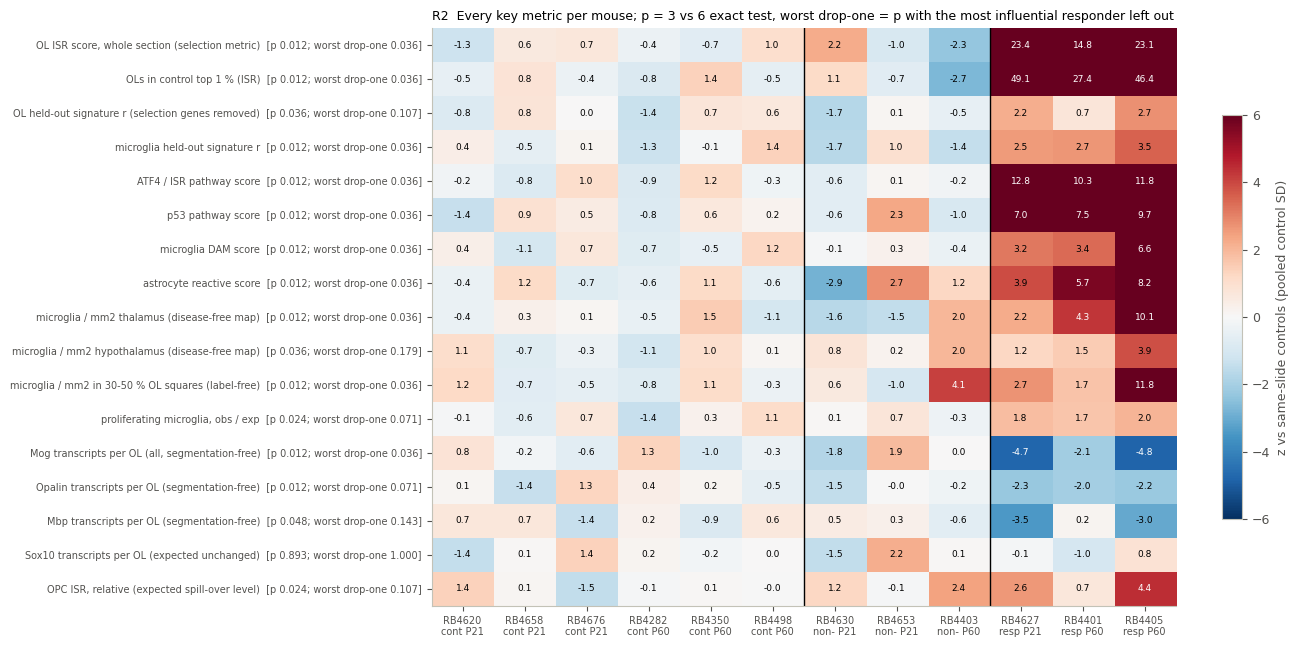

In [3]:
cells = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz").rename(columns={"RBD_compartment_simplified": "region"})
lab = pd.read_csv(REPO / "results" / "region_map" / "region_transfer_labels.csv.gz", usecols=["cell_id", "sample_id", "region_new"])
cells = cells.merge(lab, on=["cell_id", "sample_id"])
cells["cell_type"] = cells.cell_class.replace({"DA-Oligodendrocytes": "Oligodendrocytes"})
gs = pd.read_csv(REPO / "results" / "cell_table" / "cell_gene_scores.csv.gz", usecols=["cell_id", "sample_id", "cell_type", "DAM", "ASTRO_REACTIVE", "MHC1"])
dens = co.region_density(cells.assign(region=cells.region_new))
mgd = lambda r: dens[(dens.cell_type == "Microglia") & (dens.region == r)].set_index("sample_id").density.reindex(order).fillna(0)
tx = pd.read_csv(REPO / "results" / "ol_mechanism" / "tables" / "myelin_tx_by_region.csv")
per_ol = lambda g: (tx[tx.gene == g].groupby("sample_id").n.sum() / cells[cells.cell_type == "Oligodendrocytes"].groupby("sample_id").size()).reindex(order)
tails = pd.read_csv(REPO / "results" / "mosaic" / "tables" / "tail_enrichment.csv")
OLL = pseudobulk_log(["Oligodendrocytes", "DA-Oligodendrocytes"], min_cpm=0)
def pathway(name):
    g = [x for x in MECHANISM_SETS[name] if x in OLL]
    Z = OLL[g].copy()
    for a in (21, 60):
        ss = [s for s in order if age[s] == a]; Z.loc[ss] = OLL.loc[ss, g] - OLL.loc[[c for c in ctrl if age[c] == a], g].mean()
    return Z.mean(1)
M = {  # metric: (values, expected direction, finding)
    "OL ISR score, whole section (selection metric)": (sections.isr_cpm.reindex(order), 1, "1"),
    "OLs in control top 1 % (ISR)": (tails[tails.score == "isr"].set_index("sample_id").excess_q99.reindex(order), 1, "12"),
    "OL held-out signature r (selection genes removed)": (sig["OLs, selection genes removed"], 1, "A"),
    "microglia held-out signature r": (sig["microglia"], 1, "A"),
    "ATF4 / ISR pathway score": (pathway("ATF4 / ISR"), 1, "16"),
    "p53 pathway score": (pathway("p53 targets"), 1, "16"),
    "microglia DAM score": (gs[gs.cell_type == "Microglia"].groupby("sample_id").DAM.mean().reindex(order), 1, "5/15"),
    "astrocyte reactive score": (gs[gs.cell_type == "Astrocytes"].groupby("sample_id").ASTRO_REACTIVE.mean().reindex(order), 1, "5/15"),
    "microglia / mm2 thalamus (disease-free map)": (mgd("Thalamus"), 1, "14"),
    "microglia / mm2 hypothalamus (disease-free map)": (mgd("Hypothalamus"), 1, "14"),
    "microglia / mm2 in 30-50 % OL squares (label-free)": (pd.read_csv(REPO / "results" / "composition" / "tables" / "microglia_density_by_ol_fraction.csv", index_col=0)["30%-50%"].reindex(order), 1, "14"),
    "proliferating microglia, obs / exp": (pd.read_csv(REPO / "results" / "composition" / "tables" / "microglia_proliferation.csv", index_col=0).obs_over_exp.reindex(order), 1, "14"),
    "Mog transcripts per OL (all, segmentation-free)": (per_ol("Mog"), -1, "16"),
    "Opalin transcripts per OL (segmentation-free)": (per_ol("Opalin"), -1, "16"),
    "Mbp transcripts per OL (segmentation-free)": (per_ol("Mbp"), -1, "16"),
    "Sox10 transcripts per OL (expected unchanged)": (per_ol("Sox10"), 0, "16"),
    "OPC ISR, relative (expected spill-over level)": (pd.read_csv(REPO / "results" / "ol_mechanism" / "tables" / "isr_by_lineage_stage.csv", index_col=0).iloc[:, 0].reindex(order), 0, "16"),
}
rows, Zm = [], {}
for name, (v, d, f) in M.items():
    v = v.astype(float)
    Zm[name] = rb.slide_z(v, age, ctrl)
    r = rb.loro(v, resp, ctrl, direction=d if d != 0 else 1)
    rows.append({"metric": name, "finding": f, "expected": {1: "up", -1: "down", 0: "none"}[d], **r,
                 "nonresp_p": co.exact_perm(v, nonr, ctrl)[1]})
lo = save_table(pd.DataFrame(rows).set_index("metric").round(3), "leave_one_responder_out")
Zm = save_table(pd.DataFrame(Zm).T[order].round(2), "metric_z_by_mouse")

fig, ax = plt.subplots(figsize=(12, 7.5))
im = ax.imshow(Zm.clip(-6, 6), cmap="RdBu_r", vmin=-6, vmax=6, aspect="auto")
for i in range(Zm.shape[0]):
    for j in range(Zm.shape[1]):
        ax.text(j, i, f"{Zm.iat[i, j]:.1f}", ha="center", va="center", fontsize=6.5, color="w" if abs(Zm.iat[i, j]) > 4 else "k")
ax.set_xticks(range(len(order)), [f"{s}\n{grp[s][:4]} P{age[s]}" for s in order], fontsize=7)
ax.set_yticks(range(Zm.shape[0]), [f"{m}  [p {lo.loc[m, 'p_all']:.3f}; worst drop-one {lo.loc[m, 'p_worst_drop_one']:.3f}]" for m in Zm.index], fontsize=7)
for x in (len(ctrl) - 0.5, len(ctrl) + len(nonr) - 0.5): ax.axvline(x, color="k", lw=1)
fig.colorbar(im, ax=ax, shrink=0.7, label="z vs same-slide controls (pooled control SD)")
ax.set_title("R2  Every key metric per mouse; p = 3 vs 6 exact test, worst drop-one = p with the most influential responder left out", fontsize=9)
save(fig, "R2_metric_matrix")
display(lo[["finding", "expected", "p_all", "p_worst_drop_one", "dropped_for_worst", "n_beyond_control_range", "nonresp_p"]])

**B.** Read across a row: for metrics expected to change, all three responders should be red (or blue) with
controls and non-responders pale.

* **Robust to leaving out any one responder** (all three beyond the control range; p = 0.036, the 2-vs-6 minimum,
  whichever responder is dropped): OL ISR score, OL top-1 % excess, ATF4 and p53 pathway scores, microglial DAM,
  astrocyte reactivity, the microglia held-out signature, thalamus microglia density (disease-free map), microglia
  density in OL-rich squares (label-free) and Mog per OL.
* **Consistent but weaker** (all three responders beyond the control range, worst drop-one p = 0.071): proliferating
  microglia and Opalin per OL.
* **Carried by two responders**: the OL held-out signature and Mbp per OL (RB4401 inside the control range),
  hypothalamus microglia density (worst drop-one p = 0.18). RB4401 is the mildest responder in nearly every readout.
* **Expected-null metrics**: Sox10 per OL does not move (p = 0.89). OPC ISR is mildly but consistently up (p = 0.024),
  at the same size as in astrocytes, which is what spill-over from neighbouring stressed OLs predicts (analysis/13).
* Non-responders: no metric separates them from controls (all p >= 0.27). RB4403's high label-free microglia density
  (z = 4.1) reflects its over-segmentation (doubled cell count), not microgliosis.

## C. Multiple testing

In [4]:
fam = []
d = pd.read_csv(REPO / "results" / "composition" / "tables" / "density_tests.csv")
d = d[d.metric == "density"]; fam.append(d.assign(family="11 densities (7 types x 6 regions)", test=d.cell_type + " | " + d.region)[["family", "test", "p_resp"]])
d = pd.read_csv(REPO / "results" / "region_map" / "tables" / "regional_results_both_maps.csv"); d = d[d["map"] == "disease_free"]
fam.append(d.assign(family="14 regional results, new map", test=d.metric + " | " + d.region)[["family", "test", "p_resp"]])
d = pd.read_csv(REPO / "results" / "ol_mechanism" / "tables" / "myelin_tx_tests.csv"); d = d[d.metric == "per_ol"]
fam.append(d.assign(family="13 transcripts per OL (13 genes x 5 regions)", test=d.gene + " | " + d.region)[["family", "test", "p_resp"]])
d = pd.read_csv(REPO / "results" / "ol_mechanism" / "tables" / "pathway_scores.csv")
fam.append(d.assign(family="13 OL pathway scores", test=d.pathway)[["family", "test", "p_resp"]])
fam.append(lo.reset_index().assign(family="15 key metrics (this notebook)", test=lambda x: x.metric, p_resp=lambda x: x.p_all)[["family", "test", "p_resp"]])
fam = pd.concat(fam, ignore_index=True)
fam["q_within_family"] = fam.groupby("family").p_resp.transform(rb.bh)
fam["q_all"] = rb.bh(fam.p_resp)
fam = save_table(fam.round(4), "multiple_testing", index=False)
summ = fam.groupby("family").agg(n_tests=("test", "size"), p_lt_05=("p_resp", lambda p: (p < 0.05).sum()),
                                 q_lt_10_within=("q_within_family", lambda q: (q < 0.10).sum()), q_lt_10_all=("q_all", lambda q: (q < 0.10).sum()))
display(summ)
display(fam[(fam.p_resp < 0.05) & (fam.q_within_family >= 0.10)].sort_values(["family", "p_resp"]))

,n_tests,p_lt_05,q_lt_10_within,q_lt_10_all
family,,,,
11 densities (7 types x 6 regions),42,6,0,6
13 OL pathway scores,11,11,11,11
13 transcripts per OL (13 genes x 5 regions),65,44,45,44
"14 regional results, new map",16,10,10,10
15 key metrics (this notebook),17,16,16,16


,family,test,p_resp,q_within_family,q_all
0,11 densities (7 types x 6 regions),Microglia | Thalamus,0.0119,0.2499,0.0318
1,11 densities (7 types x 6 regions),Microglia | Fiber tracts,0.0119,0.2499,0.0318
32,11 densities (7 types x 6 regions),Excitatory Neurons | Hypothalamus,0.0238,0.2499,0.0533
37,11 densities (7 types x 6 regions),Neurons | Fiber tracts,0.0238,0.2499,0.0533
7,11 densities (7 types x 6 regions),Oligodendrocytes | Fiber tracts,0.0357,0.2499,0.0663
10,11 densities (7 types x 6 regions),Oligodendrocytes | Cortex,0.0357,0.2499,0.0663


**C.** With exact tests on 3 vs 6 mice p cannot go below 0.012, so false-discovery control depends on how many tests in
a family reach that floor.

* **OL pathway scores (11 / 11), transcripts per OL (45 of 65), regional results on the new map (10 / 16) and the key
  metrics of this notebook (16 / 17) keep q < 0.10.**
* **The 42-test density screen of analysis/11 does not survive on its own**: only 6 tests have p < 0.05, and the two at
  the floor (microglia in thalamus and fibre tracts) reach q = 0.25. The microgliosis claim therefore rests on its
  replication in two framings that are not part of that screen: the label-free OL-rich squares and the disease-free
  map (both q < 0.10), and on the per-mouse robustness in B. The modest OL density drops (cortex, fibre tracts) and the
  neuron "changes" in that screen should be treated as nominal; the README calls them "at most modest".

## D. Reproducibility

In [5]:
ignored = subprocess.run(["git", "ls-files", "--others", "--ignored", "--exclude-standard", "results"], cwd=REPO, capture_output=True, text=True).stdout.split()
gi_lines = (REPO / ".gitignore").read_text().splitlines()
def regen(path):
    # the comment line just above the matching .gitignore pattern says how to recreate it
    for i, l in enumerate(gi_lines):
        pat = l.strip()
        if pat and not pat.startswith("#") and (Path(path).match(pat) or path.startswith(pat.rstrip("/"))):
            j = i - 1
            while j >= 0 and not gi_lines[j].startswith("#"): j -= 1
            return gi_lines[j].lstrip("# ").strip() if j >= 0 else ""
    return ""
rows = []
for nbp in sorted(p for p in (REPO / "analysis").glob("*.ipynb") if not p.name.startswith("_")):
    nb = json.loads(nbp.read_text())
    src = "\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")
    errors = sum(o.get("output_type") == "error" for c in nb["cells"] if c["cell_type"] == "code" for o in c.get("outputs", []))
    unexecuted = sum(c["cell_type"] == "code" and c.get("execution_count") is None for c in nb["cells"])
    needs = sorted({f for f in ignored if Path(f).name in src and not any(x in f for x in ("figures/", "superseded"))})
    rows.append({"notebook": nbp.name, "errors": errors, "unexecuted_cells": unexecuted,
                 "gitignored_inputs": "; ".join(Path(f).name for f in needs) or "-",
                 "how_to_regenerate": " | ".join(sorted({regen(f) for f in needs} - {""})) or "-"})
repro = save_table(pd.DataFrame(rows).set_index("notebook"), "reproducibility")
display(repro)

,errors,unexecuted_cells,gitignored_inputs,how_to_regenerate
notebook,,,,
01-region-time-treatment-figures.ipynb,0,0,-,-
02-ol-response-and-classifiers.ipynb,0,0,cells.csv.gz; ol_gene_scores.csv.gz,Per-cell metadata + centroids (18 MB); recreat...
03-ol-stress-genes.ipynb,0,0,-,-
04-neighbourhood-and-staging.ipynb,0,0,cell_gene_scores.csv.gz; cells.csv.gz,Per-cell metadata + centroids (18 MB); recreat...
05-design-power.ipynb,0,0,-,-
06-borders-patches-repair-neurons.ipynb,0,0,cell_gene_scores.csv.gz; cells.csv.gz,Per-cell metadata + centroids (18 MB); recreat...
07-responder-probability.ipynb,0,0,-,-
08-t-cells.ipynb,0,0,cells.csv.gz,Per-cell metadata + centroids (18 MB); recreat...
09-mosaic-response.ipynb,0,0,ol_gene_scores.csv.gz,Per-cell metadata + centroids (18 MB); recreat...


**D.** All notebooks are executed without errors. Those that read gitignored inputs say how to regenerate them
(.gitignore comments, README "Steps"); most of those inputs come from the h5ad or the raw Xenium folders on the
office Mac (`scripts/export_*.py`), plus the large region x time pseudobulk tables (`scripts/run_region_time_de.py`).
A fresh clone can open every notebook with its figures; re-running notebooks 08-15 needs those exports first.

## E. Region DE (analysis/01) on the disease-free region map

n_sig_new       n_sig_old      
age                                             21    60        21    60
cell_type                   region                                      
Astrocytes                  Cortex             2.0   4.0       2.0   3.0
                            Fiber tracts       1.0   0.0       0.0   0.0
                            Hypothalamus      13.0  15.0      13.0   9.0
                            Pallidum           0.0   0.0       0.0   0.0
                            Striatum           0.0   1.0       0.0  29.0
                            Thalamus           1.0   1.0       1.0   2.0
DA-Oligodendrocytes         Thalamus           0.0   1.0       NaN   1.0
Endothelial Cells           Cortex             2.0   5.0       2.0   4.0
                            Fiber tracts       1.0   1.0       1.0   1.0
                            Hypothalamus       3.0   4.0       3.0   3.0
                            Pallidum           0.0   0.0       0.0   0.0
                            Striatum           3.0   1.0       4.0  10.0
                            Thalamus           2.0   8.0       2.0   6.0
Immature Oligodendrocytes I Cortex             0.0   1.0       0.0   1.0
                            Fiber tracts       0.0   0.0       0.0   0.0
                            Hypothalamus       1.0   1.0       1.0   1.0
                            Pallidum           0.0   0.0       0.0   NaN
                            Striatum           1.0   0.0       0.0   0.0
                            Thalamus           1.0   1.0       1.0   2.0
Microglia                   Cortex             0.0   0.0       0.0   0.0
                            Fiber tracts       0.0   0.0       1.0   0.0
                            Hypothalamus       0.0  24.0       0.0  12.0
                            Pallidum           0.0   0.0       0.0   0.0
                            Striatum          12.0   0.0      10.0   1.0
                            Thalamus           0.0   0.0       0.0   1.0
Oligodendrocytes            Cortex             0.0   0.0       0.0   1.0
                            Fiber tracts       2.0   1.0       1.0   3.0
                            Hypothalamus      10.0   7.0      13.0   5.0
                            Pallidum           0.0   1.0       0.0   0.0
                            Striatum           3.0   1.0       4.0   1.0
                            Thalamus           0.0   7.0       0.0   4.0

,cell_type,region,r_log2FC
42,GABAergic Neurons,Vasculature,0.313388
29,Excitatory Neurons,Meningeal border/glia limitans,0.508624
100,Oligodendrocytes,Vasculature,0.551616
88,Neurons,Vasculature,0.556556
40,GABAergic Neurons,Pallidum,0.569765
32,Excitatory Neurons,Vasculature,0.610162
7,Astrocytes,Pallidum,0.614430
21,Endothelial Cells,Pallidum,0.616118
50,Immature Oligodendrocytes I,Pallidum,0.622485
80,Neurons,Fiber tracts,0.627330


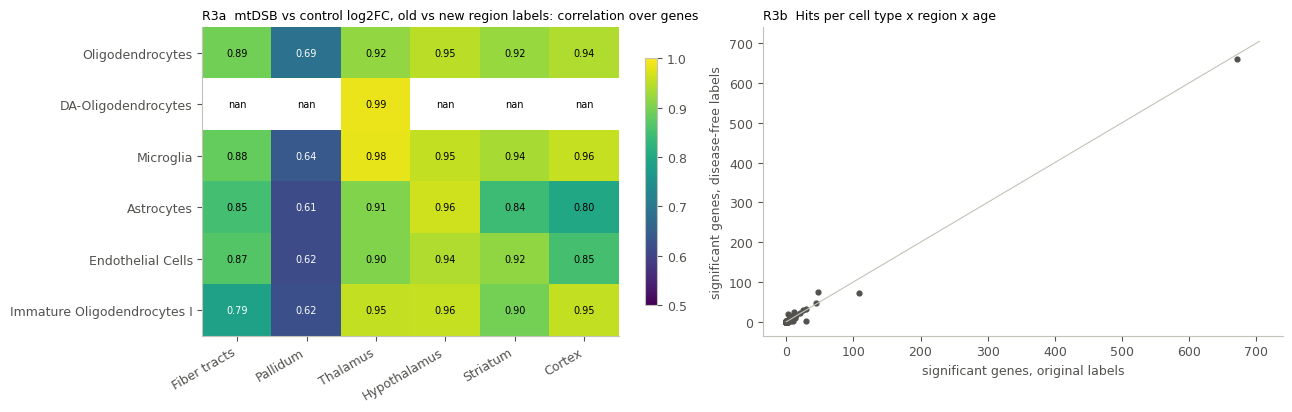

In [6]:
NEW = REPO / "results" / "region_time_disease_free"
old_s = pd.read_csv(RT / "summary_by_region_age.csv"); new_s = pd.read_csv(NEW / "summary_by_region_age.csv")
cmp_ = old_s.merge(new_s, on=["cell_type", "region", "age"], how="outer", suffixes=("_old", "_new"))
cmp_ = save_table(cmp_[["cell_type", "region", "age", "n_sig_old", "n_sig_new", "n_tested_old", "n_tested_new"]], "region_de_old_vs_new", index=False)
REGS = ["Fiber tracts", "Pallidum", "Thalamus", "Hypothalamus", "Striatum", "Cortex"]
TYPES = ["Oligodendrocytes", "DA-Oligodendrocytes", "Microglia", "Astrocytes", "Endothelial Cells", "Immature Oligodendrocytes I"]
piv = cmp_[cmp_.cell_type.isin(TYPES) & cmp_.region.isin(REGS)].pivot_table(index=["cell_type", "region"], columns="age", values=["n_sig_old", "n_sig_new"])
display(piv)

old_d = pd.read_csv(RT / "de_condition_by_region_age.csv", usecols=["cell_type", "region", "age", "gene", "log2FC", "padj"])
new_d = pd.read_csv(NEW / "de_condition_by_region_age.csv", usecols=["cell_type", "region", "age", "gene", "log2FC", "padj"])
j = old_d.merge(new_d, on=["cell_type", "region", "age", "gene"], suffixes=("_old", "_new"))
rc = j.groupby(["cell_type", "region"]).apply(lambda d: np.corrcoef(d.log2FC_old, d.log2FC_new)[0, 1], include_groups=False).rename("r_log2FC")
rc = save_table(rc.reset_index(), "region_de_lfc_correlation", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
t = rc[rc.cell_type.isin(TYPES) & rc.region.isin(REGS)].pivot(index="cell_type", columns="region", values="r_log2FC").loc[TYPES, REGS]
im = axes[0].imshow(t, cmap="viridis", vmin=0.5, vmax=1, aspect="auto")
for a in range(t.shape[0]):
    for b in range(t.shape[1]):
        axes[0].text(b, a, f"{t.iat[a, b]:.2f}", ha="center", va="center", fontsize=7, color="w" if t.iat[a, b] < 0.8 else "k")
axes[0].set_xticks(range(len(REGS)), REGS, rotation=30, ha="right"); axes[0].set_yticks(range(len(TYPES)), TYPES)
axes[0].set_title("R3a  mtDSB vs control log2FC, old vs new region labels: correlation over genes", fontsize=9)
fig.colorbar(im, ax=axes[0], shrink=0.8)
o = cmp_[cmp_.region != "All regions"]
axes[1].scatter(o.n_sig_old, o.n_sig_new, s=12, color=INK2)
for _, r in o[(o.region.isin(["Fiber tracts", "Pallidum"])) & (o[["n_sig_old", "n_sig_new"]].max(1) > 20)].iterrows():
    axes[1].annotate(f"{r.cell_type[:12]} | {r.region} | P{r.age}", (r.n_sig_old, r.n_sig_new), fontsize=6)
mx = np.nanmax(o[["n_sig_old", "n_sig_new"]].to_numpy()) * 1.05
axes[1].plot([0, mx], [0, mx], color=AXIS, lw=0.8); axes[1].set_xlabel("significant genes, original labels"); axes[1].set_ylabel("significant genes, disease-free labels")
axes[1].set_title("R3b  Hits per cell type x region x age", fontsize=9)
fig.tight_layout(); save(fig, "R3_region_de_old_vs_new")
display(rc.sort_values("r_log2FC").head(12))

**E.** analysis/01 compares all six mtDSB mice (responders and non-responders) with controls per region and age.
Re-run with the disease-free region labels (`scripts/run_region_time_de.py --region-labels`, results in
`results/region_time_disease_free/`):

* The total number of significant genes barely changes (2,024 -> 2,007) and log2 fold changes correlate at 0.92-0.95 in
  thalamus, cortex, hypothalamus, hippocampus and striatum, 0.87 in fibre tracts and 0.62 in pallidum (which held almost
  no responder cells under the old map).
* The largest shifts are in striatum (e.g. astrocytes at P60: 29 -> 1 significant genes; neurons and endothelial cells
  also drop) and hypothalamus (microglia at P60: 12 -> 24). The old striatum hits partly came from tissue that the old
  map had assigned wrongly.
* So the region x age results of analysis/01 stand overall; for striatum, fibre tracts and pallidum use the new run.

## Summary

* **Circularity**: the three responders share a common response in microglia, a cell type never used to call them
  (complete separation), and in OLs on genes excluded from the call (RB4405, RB4627 clearly; RB4401 weakly).
* **n = 3**: the core claims (OL ISR / ATF4 / p53, OL top-1 % excess, microglial DAM, astrocyte reactivity, thalamus and
  white-matter microgliosis, Mog loss) hold with any one responder left out and with every responder beyond the
  control range. Mbp loss, hypothalamus microgliosis and the OL non-ISR signature are carried by RB4405 and RB4627.
* **Multiple testing**: pathway, myelin-transcript, regional and key-metric families keep FDR < 0.10; the analysis/11
  density screen does not on its own, so microgliosis rests on its label-free and disease-free-map replications.
* **Reproducibility**: all 15 notebooks run without errors; gitignored inputs are documented with how to regenerate.
* **Region DE**: robust to the corrected region map except for striatum / fibre tracts / pallidum hit lists.